In [1]:
import os
import sys
import warnings

sys.path.append("/path/to/GeneSPOT")
warnings.filterwarnings("ignore")
os.environ['R_HOME'] = '/path/to/R'

In [2]:
from pathlib import Path
import seaborn as sns
import numpy as np
import pandas as pd
import scanpy as sc
from tqdm import tqdm
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

matplotlib.rcParams['pdf.fonttype'] = 42

In [3]:
from palettable.colorbrewer.diverging import Spectral_11_r

In [4]:
%load_ext autoreload
%autoreload 2

from genespot.utils import seed_everything
from genespot.genespot import topk_similar
from genespot.optimal_transports import cal_ot_distance
from genespot.graph_representation import node2vec
from genespot.visualization import create_cmap

random_state = 42
seed_everything(random_state)

In [5]:
RES_DIR = Path('/path/to/GeneSPOT/reproduce/fig3/res/unpaired')
OUTPUTS_DIR = Path('/path/to/GeneSPOT/reproduce/fig3/outputs/unpaired')

os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

In [6]:
rna_adata = sc.read_h5ad(RES_DIR / 'rna.h5ad')
rna_annotations = rna_adata.uns['selected_annotation']
rna_EMD = rna_adata.uns['selected_EMD']
rna_agged_df = rna_adata.uns['agged_df']
msi_adata = sc.read_h5ad(RES_DIR / 'metabolism.h5ad')
msi_annotations = msi_adata.uns['selected_annotation']
msi_EMD = msi_adata.uns['selected_EMD']
msi_agged_df = msi_adata.uns['agged_df']

#Genes: 786, #Msis:236


<Axes: >

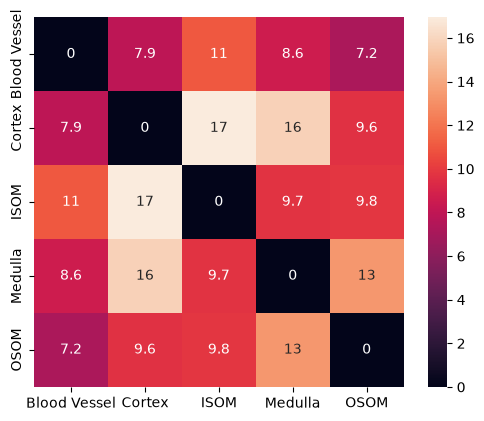

In [7]:
n_genes, n_msis = rna_agged_df.shape[1], msi_agged_df.shape[1]
print(f'#Genes: {n_genes}, #Msis:{n_msis}')
annotations = [
    'Blood Vessel',
    'Cortex',
    'ISOM',
    'Medulla', 
    'OSOM'
]
EMD = np.mean([rna_EMD, msi_EMD], axis=0)
sns.heatmap(EMD, xticklabels=annotations, yticklabels=annotations, annot=True, square=True)

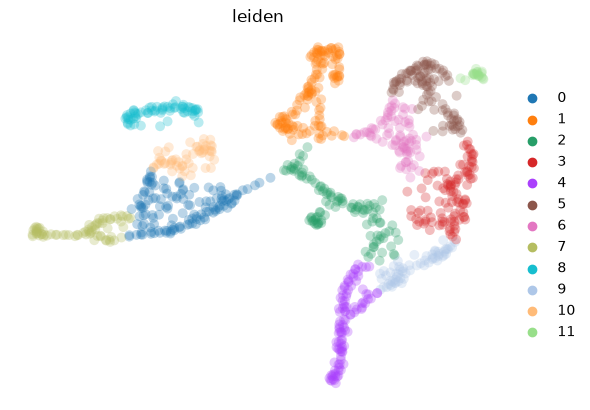

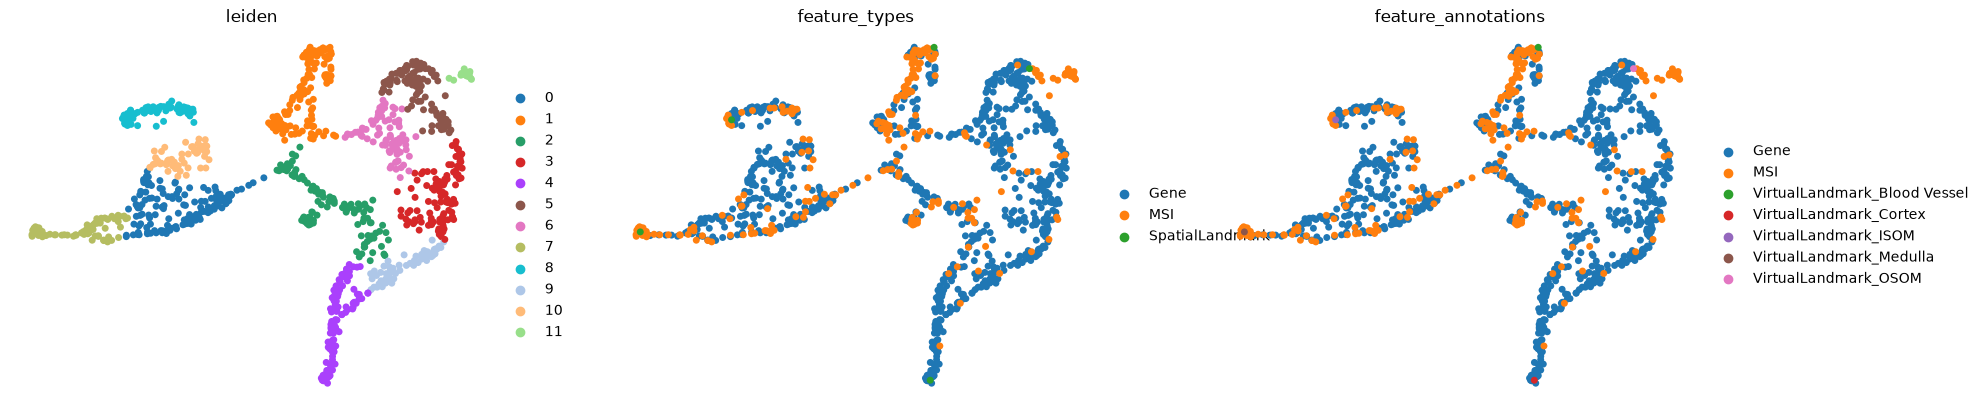

In [8]:
if not os.path.exists(RES_DIR / 'fdata.h5ad'):
    agged_df = pd.concat([rna_agged_df, msi_agged_df], axis=1).loc[annotations]
    for i, ann in enumerate(annotations):
        c_onehot = np.zeros((len(annotations),)).astype(float)
        c_onehot[i] = 1
        agged_df[f'SpatialLandmark_{ann}'] = c_onehot
    
    agged_x = agged_df.loc[annotations, :].values
    feature_distance = cal_ot_distance(
        agged_x, 
        EMD,
        processes=None
    )

    feature_embedding, _, losses = node2vec(
        feature_distance,
        dimensions=30,
        n_neighbors=20,
        walk_length=10,
        context_size=10,
        num_walks=500,
        num_negative_samples=1,
        p=1, q=0.5,

        workers=5,
        epochs=200,
        lr=1e-2,
        device='cuda:0',
        norm=True
    )

    fig, ax = plt.subplots(1, 1, figsize=(4, 1.5))
    ax.plot(range(len(losses)), losses)
    plt.show()

    feature_names = agged_df.columns.tolist()
    feature_types = ['Gene'] * n_genes + ['MSI'] * n_msis + ['SpatialLandmark'] * len(annotations)
    feature_annotations = ['Gene'] * n_genes + ['MSI'] * n_msis + [f'VirtualLandmark_{ann}' for ann in annotations]

    gdata = sc.AnnData(feature_embedding)
    gdata.obsm['feature_embedding'] = feature_embedding
    gdata.obs_names = feature_names
    gdata.obs['feature_names'] = feature_names
    gdata.obs['feature_types'] = feature_types
    gdata.obs['feature_annotations'] = feature_annotations

    sc.pp.neighbors(gdata, random_state=random_state, use_rep='feature_embedding', n_neighbors=20)
    sc.tl.umap(gdata, random_state=random_state)
    sc.tl.leiden(gdata, resolution=0.5, random_state=random_state)
    gdata.write_h5ad(RES_DIR / 'fdata.h5ad')
else:
    gdata = sc.read_h5ad(RES_DIR / 'fdata.h5ad')
sc.pl.umap(gdata, color='leiden', edges=False, frameon=False, size=200, alpha=0.3)
sc.pl.umap(gdata, color=['leiden', 'feature_types', 'feature_annotations'], edges=False, frameon=False, alpha=1, size=100)    

In [9]:
gdata.obs[['UMAP_x', 'UMAP_y']] = gdata.obsm['X_umap']

feature_landmark_distance = []
feature_landmark = []
for feature in gdata.obs['feature_names']:
    landmark, distance, _ = topk_similar(
        query=feature, 
        gdata=gdata, 
        n=1,
        ftype='SpatialLandmark', 
        ftype_key='feature_types',
        query_mode='embedding',
        embedding_key='feature_embedding', 
        smaller_is_better=False,
        metric='cosine_similarity',
    ).reset_index().values[0]
    feature_landmark_distance.append(distance)
    feature_landmark.append(landmark.split('_')[1])
    
gdata.obs['landmark_distance'] = feature_landmark_distance
gdata.obs['landmark'] = feature_landmark

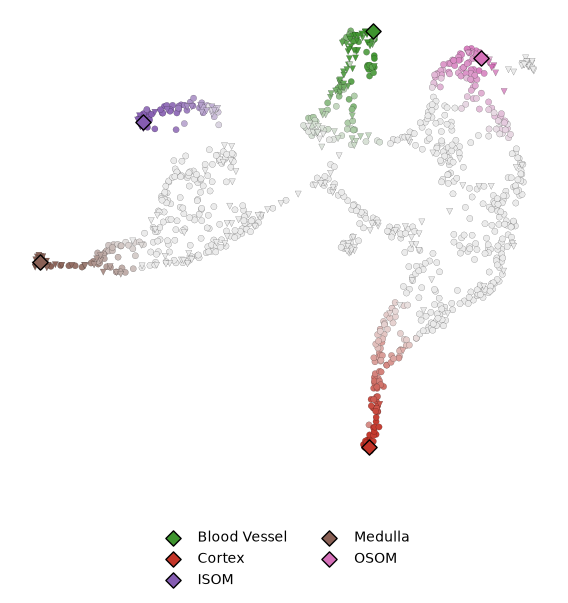

In [28]:
marker_map = {
    'Gene': 'o',
    'MSI': 'v',
    'Blood Vessel': 'D',
    'Cortex': 'D',
    'ISOM': 'D',
    'Medulla': 'D',
    'OSOM': 'D',
}
color_map = {
    'Gene': '#2f68a9',
    'MSI': '#f27d22',
    'Blood Vessel': '#3e942e',
    'Cortex': '#c33428',
    'ISOM': '#855cb2',
    'Medulla': '#896055',
    'OSOM': '#d570b9',
}

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

ploted_leidens = []
for ann in annotations:
    landmark = gdata[f'SpatialLandmark_{ann}']
    landmark_leiden = landmark.obs['leiden'].item()
    ploted_leidens.append(landmark_leiden)
    points = gdata[(gdata.obs['leiden'] == landmark_leiden) & (gdata.obs['feature_types'] != 'SpatialLandmark')]
    
    sns.scatterplot(
        data=points.obs,
        x='UMAP_x', y='UMAP_y',
        style='feature_types',
        markers=marker_map,
        palette=create_cmap(['#ebebeb', color_map[ann]], [0, 1]),
        hue=points.obs['landmark_distance'],
        # hue_norm=(0, 1),
        s=20,
        legend=None,
        edgecolors='black', linewidths=0.1
    )

    ax.scatter(
        x=landmark.obs['UMAP_x'], y=landmark.obs['UMAP_y'],
        c=color_map[ann],
        marker=marker_map[ann],
        s=60, edgecolors='black', linewidths=1,
        label=ann
    )

other_gdata = gdata[~gdata.obs['leiden'].isin(ploted_leidens)]
sns.scatterplot(
    data=other_gdata.obs,
    x='UMAP_x', y='UMAP_y',
    style='feature_types',
    markers=marker_map,
    c='#ebebeb',
    s=20,
    legend=None,
    edgecolors='black', linewidths=0.1
)

ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticks([], [])
ax.set_yticks([], [])
ax.set_title('')
ax.set_aspect(1)
# **调整图例**
legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=2,
    frameon=False
)
plt.savefig(OUTPUTS_DIR / 'fig3k.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

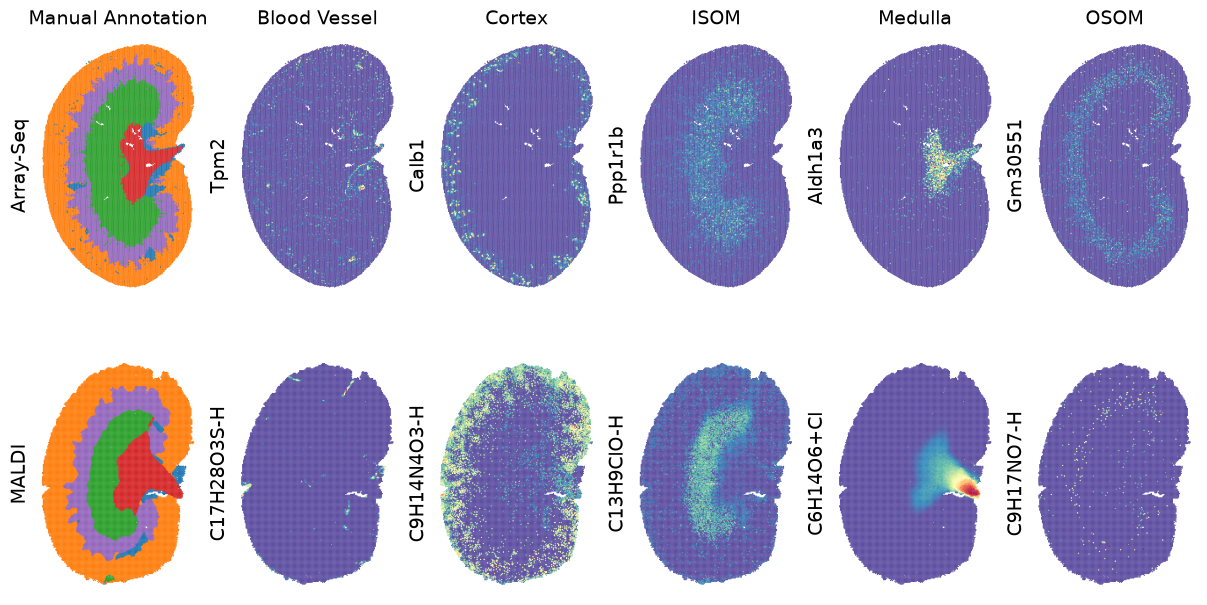

In [11]:
cmap = Spectral_11_r
fig, axs = plt.subplots(2, len(annotations)+1, figsize=(3 * len(annotations), 8))

sc.pl.embedding(rna_adata, color='Domain', basis='spatial', ax=axs[0][0], show=False, legend_loc=None)
axs[0][0].set_xlabel('')
axs[0][0].set_ylabel('')
axs[0][0].set_title('Manual Annotation', fontsize=14)
axs[0][0].spines['top'].set_visible(False)
axs[0][0].spines['bottom'].set_visible(False)
axs[0][0].spines['left'].set_visible(False)
axs[0][0].spines['right'].set_visible(False)
axs[0][0].set_aspect(1)

sc.pl.embedding(msi_adata, color='annotation', basis='spatial', ax=axs[1][0], show=False, legend_loc=None)
axs[1][0].set_xlabel('')
axs[1][0].set_ylabel('')
axs[1][0].set_title('')
axs[1][0].spines['top'].set_visible(False)
axs[1][0].spines['bottom'].set_visible(False)
axs[1][0].spines['left'].set_visible(False)
axs[1][0].spines['right'].set_visible(False)
axs[1][0].set_aspect(1)

for i, ann in enumerate(annotations):
    gene = topk_similar(
        f'SpatialLandmark_{ann}',
        gdata, 
        n=1,
        ftype='Gene',
        ftype_key='feature_types',
        query_mode='embedding', 
        embedding_key='feature_embedding', 
        metric='cosine_similarity', 
        smaller_is_better=False
    ).index.values.tolist()[0]
    
    sc.pl.embedding(
        rna_adata, 
        color=gene, basis='spatial', layer='norm',
        ax=axs[0][i+1], show=False, colorbar_loc=None,
        legend_loc=None,
        cmap=cmap.mpl_colormap)
    axs[0][i+1].set_aspect(1)
    axs[0][i+1].set_xlabel('')
    axs[0][i+1].set_ylabel(gene, fontsize=14)
    axs[0][i+1].set_title(ann, fontsize=14)
    axs[0][i+1].spines['top'].set_visible(False)
    axs[0][i+1].spines['bottom'].set_visible(False)
    axs[0][i+1].spines['left'].set_visible(False)
    axs[0][i+1].spines['right'].set_visible(False)

    msi = topk_similar(
        gene,
        gdata, 
        n=1,
        ftype='MSI',
        ftype_key='feature_types',
        query_mode='embedding', 
        embedding_key='feature_embedding', 
        metric='cosine_similarity', 
        smaller_is_better=False
    ).index.values.tolist()[0]
    
    sc.pl.embedding(
        msi_adata, 
        color=msi, 
        basis='spatial', layer='TIC',
        ax=axs[1][i+1], show=False,
        colorbar_loc=None,
        legend_loc=None,
        cmap=cmap.mpl_colormap,
        # vmax='p99'
        
    )
    axs[1][i+1].set_aspect(1)
    axs[1][i+1].set_xlabel('')
    axs[1][i+1].set_ylabel(msi, fontsize=14)
    axs[1][i+1].set_title('')
    axs[1][i+1].spines['top'].set_visible(False)
    axs[1][i+1].spines['bottom'].set_visible(False)
    axs[1][i+1].spines['left'].set_visible(False)
    axs[1][i+1].spines['right'].set_visible(False)

axs[0][0].set_ylabel('Array-Seq', fontsize=14)
axs[1][0].set_ylabel('MALDI', fontsize=14)
    
plt.subplots_adjust(hspace=0, wspace=0.2)
plt.savefig(OUTPUTS_DIR / 'fig3j.eps', format='eps', dpi=300, bbox_inches='tight')
plt.show()

Proportion (%):
Type          Metabolism  Gene
landmark                      
Medulla             45.1  54.9
Blood Vessel        53.1  46.9
ISOM                28.6  71.4
OSOM                 8.2  91.8
Cortex               4.0  96.0


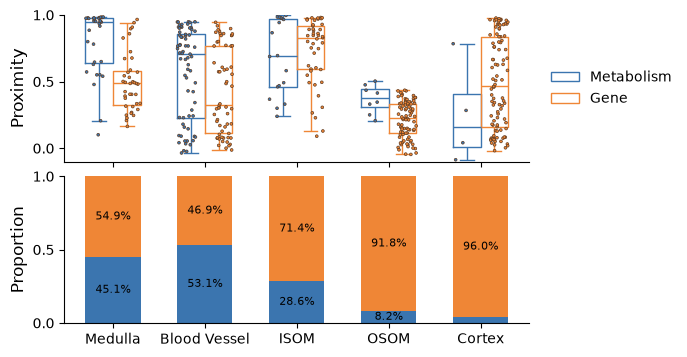

In [31]:
landmark_order = ['Medulla', 'Blood Vessel', 'ISOM', 'OSOM', 'Cortex']
type_colors = {'Gene': '#EF8636', 'Metabolism': '#3B75AF'}
type_colors_bar = {'Gene': '#EF8636', 'Metabolism': '#3B75AF'}
type_order = ['Metabolism', 'Gene']

rows = []
for ann in landmark_order:
    landmark_leiden = gdata[f'SpatialLandmark_{ann}'].obs['leiden'].item()
    pts = gdata[(gdata.obs['leiden'] == landmark_leiden) & (gdata.obs['feature_types'] != 'SpatialLandmark')]
    sub = pts.obs.copy()
    sub['landmark'] = ann
    sub['Type'] = sub['feature_types'].map({'Gene': 'Gene', 'MSI': 'Metabolism'})
    rows.append(sub)
plot_df = pd.concat(rows)
plot_df['landmark'] = pd.Categorical(plot_df['landmark'], categories=landmark_order, ordered=True)

counts = plot_df.groupby(['landmark', 'Type'], observed=True).size().unstack(fill_value=0)
prop_frac = counts.div(counts.sum(axis=1), axis=0).reindex(index=landmark_order)[type_order]
print('Proportion (%):')
print((prop_frac * 100).round(1))

fig, axs = plt.subplots(2, 1, figsize=(6, 4), sharex=True,
                        gridspec_kw={'height_ratios': [1, 1], 'hspace': 0.1})

ax_box = axs[0]
sns.boxplot(
    data=plot_df, x='landmark', y='landmark_distance', hue='Type',
    hue_order=type_order, palette=type_colors, order=landmark_order,
    ax=ax_box, fill=False, fliersize=0, width=0.6, linewidth=1.0,
)
sns.stripplot(
    data=plot_df, x='landmark', y='landmark_distance', hue='Type',
    hue_order=type_order, palette=type_colors, order=landmark_order,
    ax=ax_box, dodge=True, size=2, jitter=0.2, #alpha=0.6,
    edgecolor='#5C3A21', linewidth=0.5,
)
ax_box.set_ylabel('Proximity', fontsize=12)
ax_box.set_xlabel('')
ax_box.set_ylim(-0.1, 1)
ax_box.set_yticks([0, 0.5, 1.0])
handles, labels = ax_box.get_legend_handles_labels()
ax_box.legend(handles[:2], labels[:2], loc='center left', bbox_to_anchor=(1.02, 0.5),
              frameon=False, title=None)
ax_box.spines['top'].set_visible(False)
ax_box.spines['right'].set_visible(False)

ax_bar = axs[1]
bottom = np.zeros(len(landmark_order))
for t in type_order:
    vals = prop_frac[t].values
    ax_bar.bar(landmark_order, vals, bottom=bottom, color=type_colors_bar[t],
               edgecolor='none', width=0.6, label=t)
    for i, v in enumerate(vals):
        if v > 0.04:
            ax_bar.text(i, bottom[i] + v / 2, f'{v*100:.1f}%',
                        ha='center', va='center', fontsize=8)
    bottom += vals
ax_bar.set_ylabel('Proportion', fontsize=12)
ax_bar.set_xlabel('')
ax_bar.set_ylim(0, 1.0)
ax_bar.set_yticks([0, 0.5, 1.0])
ax_bar.spines['top'].set_visible(False)
ax_bar.spines['right'].set_visible(False)

plt.savefig(OUTPUTS_DIR / 'fig3_proximity_proportion.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()